In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

Lastes dataen for Orklas aksjekurs ned i intervallet fra starten av 2020 til slutten av 2025

[*********************100%***********************]  1 of 1 completed


Price            Close        High         Low        Open   Volume
Ticker          ORK.OL      ORK.OL      ORK.OL      ORK.OL   ORK.OL
Date                                                               
2020-01-02   62.302551   62.482618   61.568441   61.609993   797789
2020-01-03   62.122490   62.261005   61.609998   62.261005   839410
2020-01-06   61.734653   62.011678   61.332968   61.928569  1147350
2020-01-07   62.247150   62.524175   61.900871   61.970131  1387050
2020-01-08   60.751225   61.706953   60.709673   61.540741  1528284
...                ...         ...         ...         ...      ...
2025-12-19  107.036682  107.606537  106.086933  106.181914  2986764
2025-12-22  105.991959  106.941707  105.896985  106.561806  1184245
2025-12-23  106.371857  107.036678  105.991956  105.991956  1099347
2025-12-29  106.941711  107.321612  106.371864  106.656791   984208
2025-12-30  106.846733  107.511554  106.751760  107.036680  1432495

[1508 rows x 5 columns]


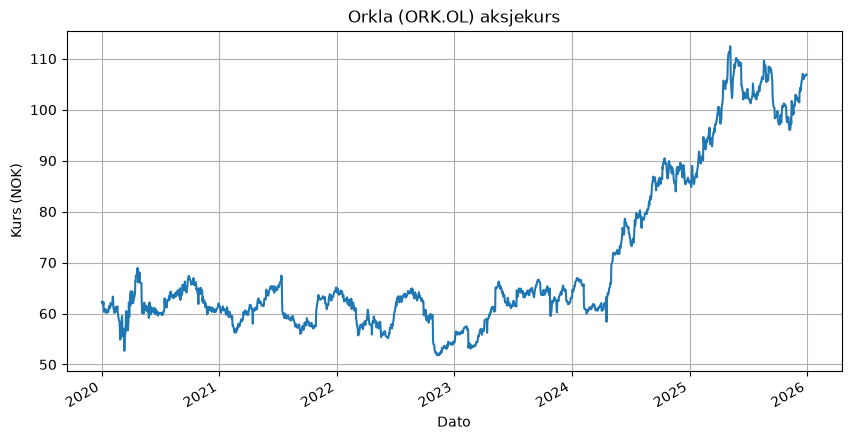

In [13]:
data = yf.download("ORK.OL", start="2020-01-01", end="2026-01-01")
print(data)

data["Close"].plot(figsize=(10, 5), legend=False)
plt.title("Orkla (ORK.OL) aksjekurs")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.grid(True)
plt.show()

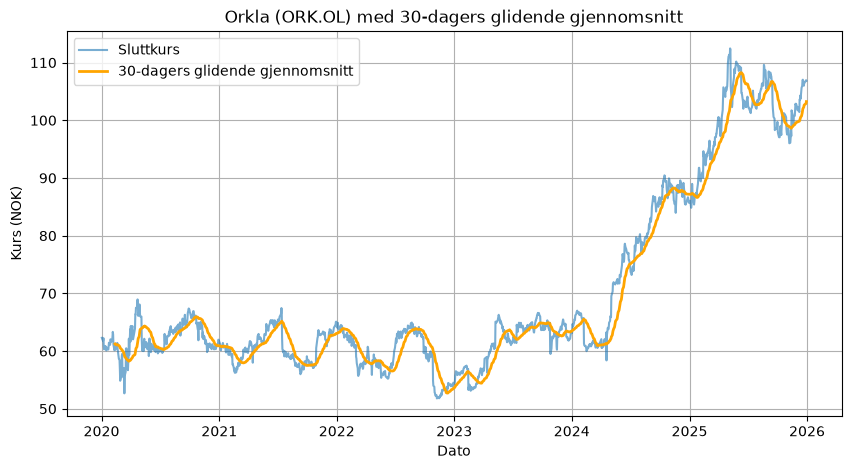

In [14]:
close = data["Close"].squeeze()
ma30 = close.rolling(window=30).mean()

plt.figure(figsize=(10, 5))
plt.plot(close, label="Sluttkurs", alpha=0.6)
plt.plot(ma30, label="30-dagers glidende gjennomsnitt", color="orange", linewidth=2)
plt.title("Orkla (ORK.OL) med 30-dagers glidende gjennomsnitt")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.legend()
plt.grid(True)
plt.show()

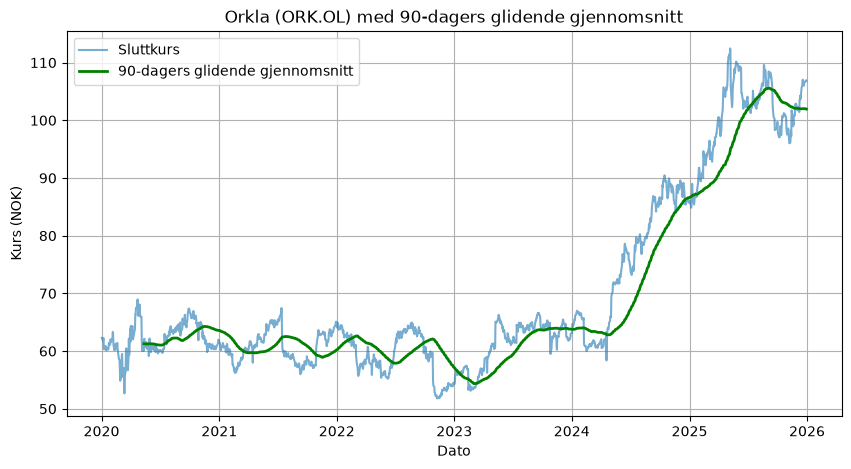

In [4]:
close = data["Close"].squeeze()
ma90 = close.rolling(window=90).mean()

plt.figure(figsize=(10, 5))
plt.plot(close, label="Sluttkurs", alpha=0.6)
plt.plot(ma90, label="90-dagers glidende gjennomsnitt", color="green", linewidth=2)
plt.title("Orkla (ORK.OL) med 90-dagers glidende gjennomsnitt")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.legend()
plt.grid(True)
plt.show()

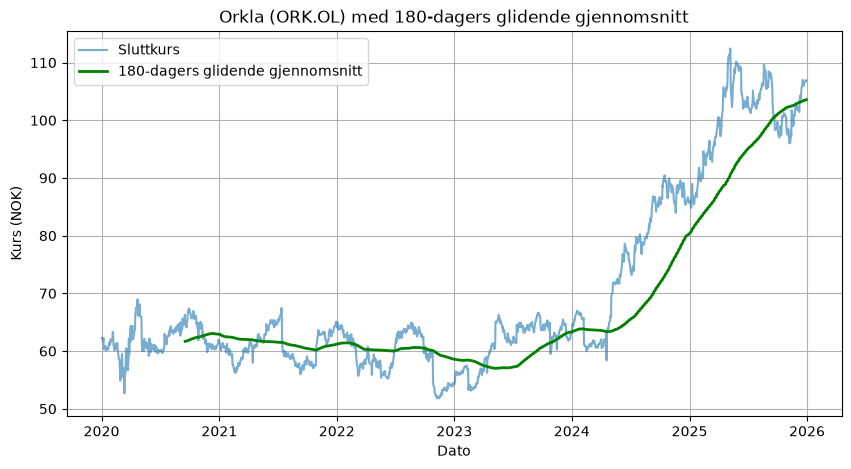

In [5]:
close = data["Close"].squeeze()
ma180 = close.rolling(window=180).mean()

plt.figure(figsize=(10, 5))
plt.plot(close, label="Sluttkurs", alpha=0.6)
plt.plot(ma180, label="180-dagers glidende gjennomsnitt", color="green", linewidth=2)
plt.title("Orkla (ORK.OL) med 180-dagers glidende gjennomsnitt")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.legend()
plt.grid(True)
plt.show()

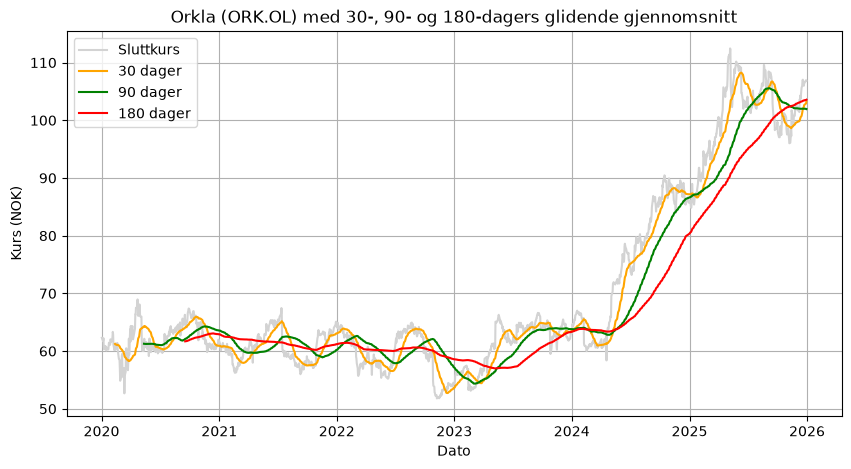

In [6]:
close = data["Close"].squeeze()
ma30 = close.rolling(window=30).mean()
ma90 = close.rolling(window=90).mean()
ma180 = close.rolling(window=180).mean()

plt.figure(figsize=(10, 5))
plt.plot(close, label="Sluttkurs", color="lightgray")
plt.plot(ma30, label="30 dager", color="orange", linewidth=1.5)
plt.plot(ma90, label="90 dager", color="green", linewidth=1.5)
plt.plot(ma180, label="180 dager", color="red", linewidth=1.5)
plt.title("Orkla (ORK.OL) med 30-, 90- og 180-dagers glidende gjennomsnitt")
plt.xlabel("Dato")
plt.ylabel("Kurs (NOK)")
plt.legend()
plt.grid(True)
plt.show()

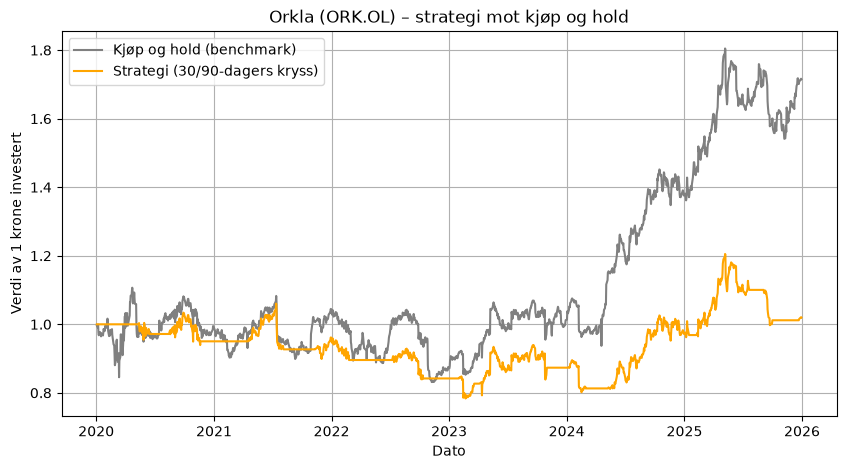

Kjøp og hold: 71.5 %
Strategi:     2.0 %


In [7]:
close = data["Close"].squeeze()
ma30 = close.rolling(window=30).mean()
ma90 = close.rolling(window=90).mean()

# Daglig avkastning
avkastning = close.pct_change()

# Strategi: eier aksjen når 30-dagers snittet ligger over 90-dagers snittet.
# shift(1) fordi signalet fra i dag først kan handles på i morgen
posisjon = (ma30 > ma90).astype(int).shift(1).fillna(0)

# Verdiutvikling av 1 krone
kjop_og_hold = (1 + avkastning).cumprod()
strategi = (1 + avkastning * posisjon).cumprod()

plt.figure(figsize=(10, 5))
plt.plot(kjop_og_hold, label="Kjøp og hold (benchmark)", color="gray")
plt.plot(strategi, label="Strategi (30/90-dagers kryss)", color="orange")
plt.title("Orkla (ORK.OL) – strategi mot kjøp og hold")
plt.xlabel("Dato")
plt.ylabel("Verdi av 1 krone investert")
plt.legend()
plt.grid(True)
plt.show()

print(f"Kjøp og hold: {(kjop_og_hold.iloc[-1] - 1) * 100:.1f} %")
print(f"Strategi:     {(strategi.iloc[-1] - 1) * 100:.1f} %")

Når 30-dagers snittet ligger over 90-dagers snittet, eier du aksjen.
Kursen har da vært høyere den siste måneden enn de siste tre månedene, altså er den på vei opp. Pengene dine er i Orkla, så verdien går opp og ned sammen med kursen. I grafen følger den oransje linjen da bevegelsene til kjøp og hold.

Når 30-dagers snittet ligger under 90-dagers snittet, har du solgt.
Kursen er da på vei ned, og strategien går ut av aksjen. Pengene står på konto uten å være investert. Vi regner med at de ikke gir noen rente, altså 0 % avkastning. Verdien endrer seg derfor ikke, uansett hva Orkla-kursen gjør, og den oransje linjen blir helt vannrett.

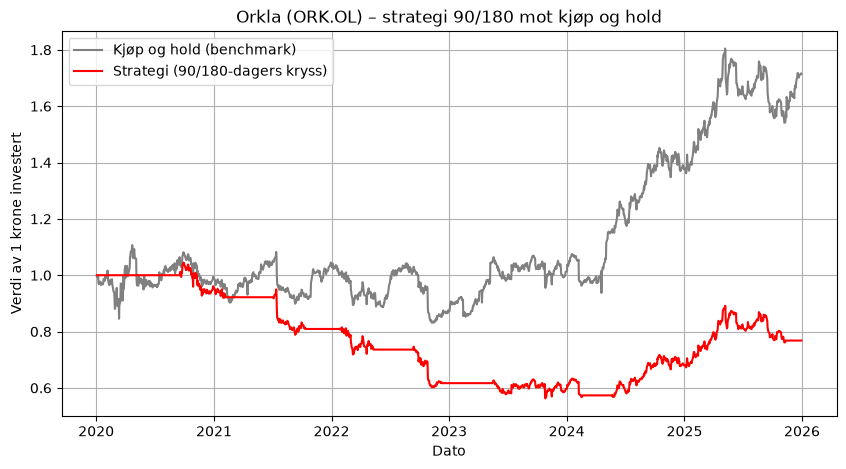

Kjøp og hold: 71.5 %
Strategi:     -23.2 %


In [8]:
close = data["Close"].squeeze()
ma90 = close.rolling(window=90).mean()
ma180 = close.rolling(window=180).mean()

# Daglig avkastning
avkastning = close.pct_change()

# Strategi: eier aksjen når 90-dagers snittet ligger over 180-dagers snittet.
# shift(1) fordi signalet fra i dag først kan handles på i morgen
posisjon = (ma90 > ma180).astype(int).shift(1).fillna(0)

# Verdiutvikling av 1 krone
kjop_og_hold = (1 + avkastning).cumprod()
strategi = (1 + avkastning * posisjon).cumprod()

plt.figure(figsize=(10, 5))
plt.plot(kjop_og_hold, label="Kjøp og hold (benchmark)", color="gray")
plt.plot(strategi, label="Strategi (90/180-dagers kryss)", color="red")
plt.title("Orkla (ORK.OL) – strategi 90/180 mot kjøp og hold")
plt.xlabel("Dato")
plt.ylabel("Verdi av 1 krone investert")
plt.legend()
plt.grid(True)
plt.show()

print(f"Kjøp og hold: {(kjop_og_hold.iloc[-1] - 1) * 100:.1f} %")
print(f"Strategi:     {(strategi.iloc[-1] - 1) * 100:.1f} %")

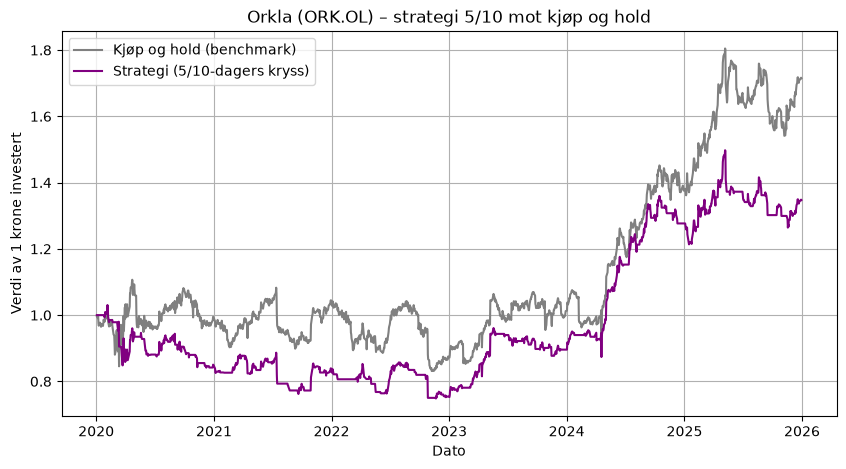

Kjøp og hold: 71.5 %
Strategi:     34.7 %
Antall handler: 165


In [15]:
close = data["Close"].squeeze()
ma5 = close.rolling(window=5).mean()
ma10 = close.rolling(window=10).mean()

# Daglig avkastning
avkastning = close.pct_change()

# Strategi: eier aksjen når 5-dagers snittet ligger over 10-dagers snittet.
# shift(1) fordi signalet fra i dag først kan handles på i morgen
posisjon = (ma5 > ma10).astype(int).shift(1).fillna(0)

# Verdiutvikling av 1 krone
kjop_og_hold = (1 + avkastning).cumprod()
strategi = (1 + avkastning * posisjon).cumprod()

plt.figure(figsize=(10, 5))
plt.plot(kjop_og_hold, label="Kjøp og hold (benchmark)", color="gray")
plt.plot(strategi, label="Strategi (5/10-dagers kryss)", color="purple")
plt.title("Orkla (ORK.OL) – strategi 5/10 mot kjøp og hold")
plt.xlabel("Dato")
plt.ylabel("Verdi av 1 krone investert")
plt.legend()
plt.grid(True)
plt.show()

print(f"Kjøp og hold: {(kjop_og_hold.iloc[-1] - 1) * 100:.1f} %")
print(f"Strategi:     {(strategi.iloc[-1] - 1) * 100:.1f} %")
print(f"Antall handler: {int(posisjon.diff().abs().sum())}")

[*********************100%***********************]  1 of 1 completed


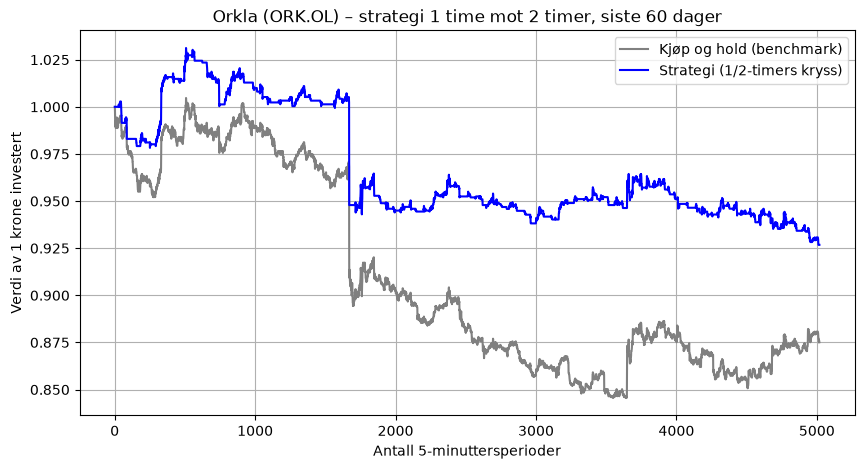

Kjøp og hold: -12.5 %
Strategi:     -7.3 %
Antall handler: 242


In [16]:
# Kurser hvert 5. minutt. Yahoo gir bare ca. 60 dager tilbake med så tett data
intradag = yf.download("ORK.OL", period="60d", interval="5m")
close = intradag["Close"].squeeze()

# 1 time = 12 perioder på 5 minutter, 2 timer = 24 perioder
ma1t = close.rolling(window=12).mean()
ma2t = close.rolling(window=24).mean()

# Avkastning per 5 minutter
avkastning = close.pct_change()

# Strategi: eier aksjen når 1-times snittet ligger over 2-timers snittet.
# shift(1) fordi signalet først kan handles på i neste periode
posisjon = (ma1t > ma2t).astype(int).shift(1).fillna(0)

# Verdiutvikling av 1 krone
kjop_og_hold = (1 + avkastning).cumprod()
strategi = (1 + avkastning * posisjon).cumprod()

plt.figure(figsize=(10, 5))
plt.plot(kjop_og_hold.values, label="Kjøp og hold (benchmark)", color="gray")
plt.plot(strategi.values, label="Strategi (1/2-timers kryss)", color="blue")
plt.title("Orkla (ORK.OL) – strategi 1 time mot 2 timer, siste 60 dager")
plt.xlabel("Antall 5-minuttersperioder")
plt.ylabel("Verdi av 1 krone investert")
plt.legend()
plt.grid(True)
plt.show()

print(f"Kjøp og hold: {(kjop_og_hold.iloc[-1] - 1) * 100:.1f} %")
print(f"Strategi:     {(strategi.iloc[-1] - 1) * 100:.1f} %")
print(f"Antall handler: {int(posisjon.diff().abs().sum())}")